# Project 12: Understanding Convolution and Pooling

## Aim
Use Python to understand how convolution filters and pooling operations extract important features from images.

## Problem description
Convolutional Neural Networks (CNNs) process images by applying small filters (kernels) that respond to patterns such as edges, lines, and textures. Pooling reduces the spatial size of a feature map while retaining important information.

## Tasks from the assignment
1. Load a sample image using Python.
2. Apply convolution filters and pooling operations.
3. Visualize and compare the original image and generated feature maps.




## 1. Import the required libraries
We use NumPy for numerical operations, Matplotlib for plots, and SciPy for convolution.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d

%matplotlib inline
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load a sample image
To keep the notebook self-contained, we create a grayscale sample image containing a bright square and diagonal lines. These shapes make edges easy to observe after convolution.

To use your own image later, load it with `plt.imread("your_image.jpg")` and convert it to grayscale if needed.

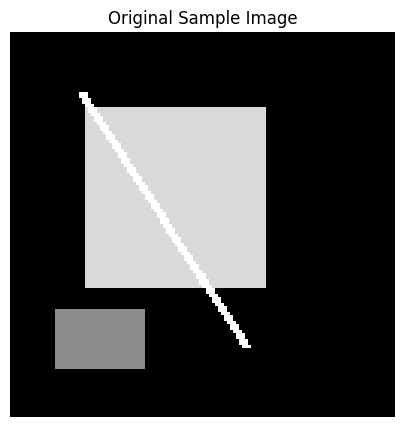

Image shape: (128, 128)


In [2]:
# Create a sample grayscale image (pixel values range from 0 to 1)
image = np.zeros((128, 128), dtype=float)
image[25:85, 25:85] = 0.85
for i in range(20, 105):
    j = int(0.65 * i + 10)
    if 0 <= j < 128:
        image[i, j:j+3] = 1.0
image[92:112, 15:45] = 0.55

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray", vmin=0, vmax=1)
plt.title("Original Sample Image")
plt.axis("off")
plt.show()
print("Image shape:", image.shape)

## 3. Understand convolution
Convolution slides a small matrix called a **kernel** or **filter** across an image. At each position, it multiplies the kernel values by the image patch and sums the results. The output is a **feature map**.

We use:
- **Sobel filter:** highlights edges.
- **Sharpen filter:** makes boundaries more prominent.
- **Blur filter:** smooths small variations.

The examples keep the output image size the same (`mode="same"`).

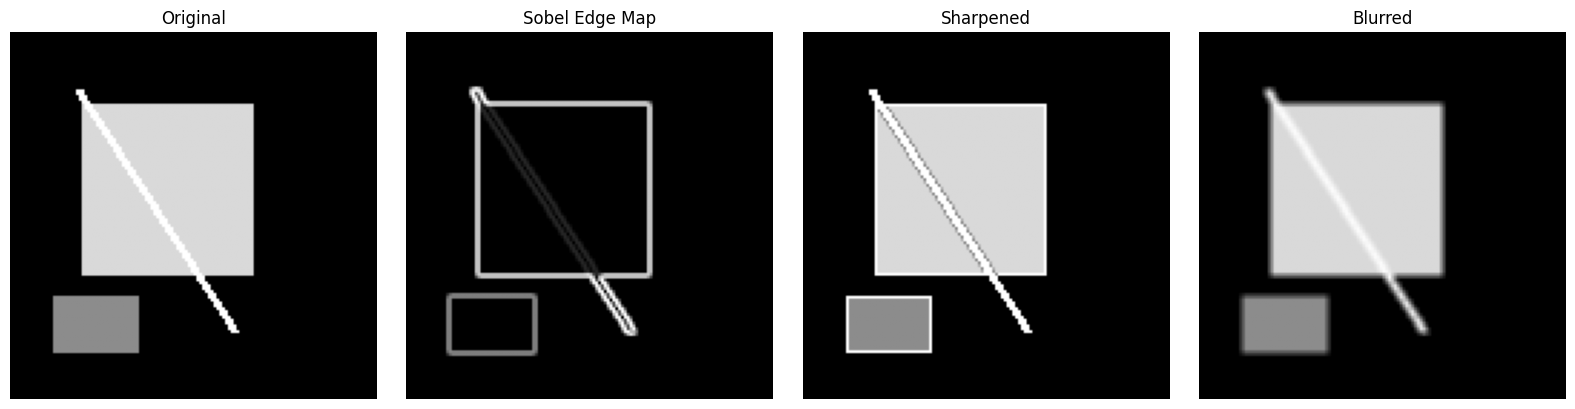

In [3]:
# Define convolution kernels
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=float)
sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=float)
blur_kernel = np.ones((3, 3), dtype=float) / 9

# Apply convolution
feature_x = convolve2d(image, sobel_x, mode="same", boundary="fill", fillvalue=0)
feature_y = convolve2d(image, sobel_y, mode="same", boundary="fill", fillvalue=0)
edge_magnitude = np.sqrt(feature_x**2 + feature_y**2)
sharpened = convolve2d(image, sharpen_kernel, mode="same", boundary="symm")
blurred = convolve2d(image, blur_kernel, mode="same", boundary="symm")
edge_display = edge_magnitude / (edge_magnitude.max() + 1e-9)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original")
axes[1].imshow(edge_display, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Sobel Edge Map")
axes[2].imshow(sharpened, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Sharpened")
axes[3].imshow(blurred, cmap="gray", vmin=0, vmax=1)
axes[3].set_title("Blurred")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Explanation of convolution results
- **Sobel edge map:** bright lines show sharp intensity changes, such as the borders of the square and diagonal line.
- **Sharpened image:** edges and boundaries become more pronounced.
- **Blurred image:** neighboring pixel values are averaged, so the image looks smoother and details become less sharp.

CNNs learn filters during training. These manually defined filters make the operations easier to understand.

## 4. Apply pooling operations
Pooling reduces the width and height of a feature map. We use a 2 × 2 window with a stride of 2:
- **Max pooling:** keeps the largest value in each 2 × 2 region.
- **Average pooling:** calculates the mean of each 2 × 2 region.

Both operations reduce the spatial dimensions by approximately half.

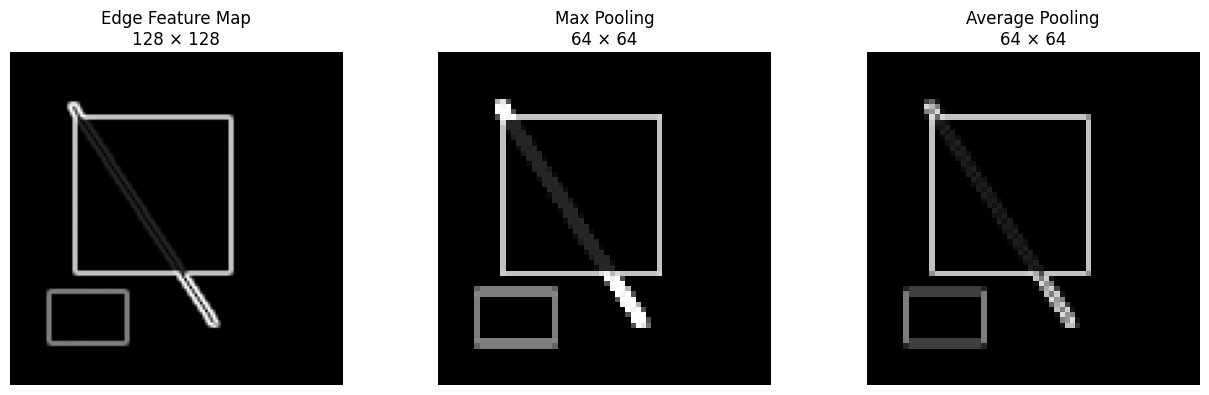

In [4]:
def pool2d(array, mode="max", window=2, stride=2):
    # Apply 2D pooling to a two-dimensional array.
    h, w = array.shape
    out_h = (h - window) // stride + 1
    out_w = (w - window) // stride + 1
    output = np.zeros((out_h, out_w), dtype=float)

    for row in range(out_h):
        for col in range(out_w):
            patch = array[row*stride:row*stride+window,
                          col*stride:col*stride+window]
            if mode == "max":
                output[row, col] = np.max(patch)
            elif mode == "average":
                output[row, col] = np.mean(patch)
            else:
                raise ValueError("mode must be 'max' or 'average'")
    return output

max_pooled = pool2d(edge_display, mode="max", window=2, stride=2)
avg_pooled = pool2d(edge_display, mode="average", window=2, stride=2)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(edge_display, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Edge Feature Map\n{edge_display.shape[1]} × {edge_display.shape[0]}")
axes[1].imshow(max_pooled, cmap="gray", vmin=0, vmax=1)
axes[1].set_title(f"Max Pooling\n{max_pooled.shape[1]} × {max_pooled.shape[0]}")
axes[2].imshow(avg_pooled, cmap="gray", vmin=0, vmax=1)
axes[2].set_title(f"Average Pooling\n{avg_pooled.shape[1]} × {avg_pooled.shape[0]}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Explanation of pooling results
- **Max pooling** preserves the strongest response in each window, so prominent edges are often retained.
- **Average pooling** smooths the feature map by averaging values in each window.
- Both pooled maps are smaller than the original feature map, reducing the amount of data later CNN layers process.

## 5. Graph: image dimensions before and after pooling
This graph compares the width and height of the feature map before pooling and after 2 × 2 pooling with stride 2.

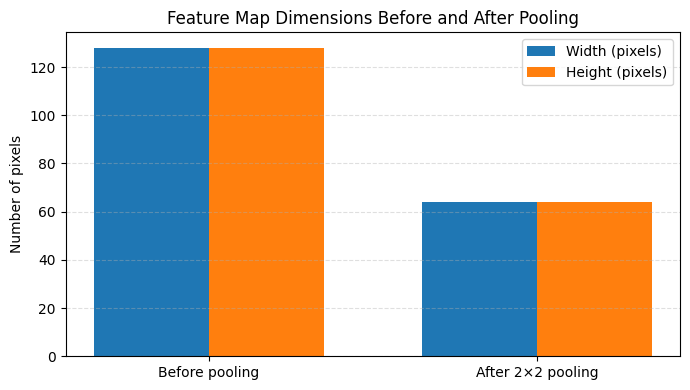

Feature map before pooling: (128, 128)
Feature map after max pooling: (64, 64)
Feature map after average pooling: (64, 64)


In [5]:
stages = ["Before pooling", "After 2×2 pooling"]
widths = [edge_display.shape[1], max_pooled.shape[1]]
heights = [edge_display.shape[0], max_pooled.shape[0]]
x = np.arange(len(stages))
bar_width = 0.35

plt.figure(figsize=(7, 4))
plt.bar(x - bar_width/2, widths, bar_width, label="Width (pixels)")
plt.bar(x + bar_width/2, heights, bar_width, label="Height (pixels)")
plt.xticks(x, stages)
plt.ylabel("Number of pixels")
plt.title("Feature Map Dimensions Before and After Pooling")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("Feature map before pooling:", edge_display.shape)
print("Feature map after max pooling:", max_pooled.shape)
print("Feature map after average pooling:", avg_pooled.shape)

## 6. Optional graph: compare pixel-value distributions
This histogram compares the edge feature map with the pooled maps. Pooling changes the distribution because values are selected (max pooling) or averaged (average pooling).

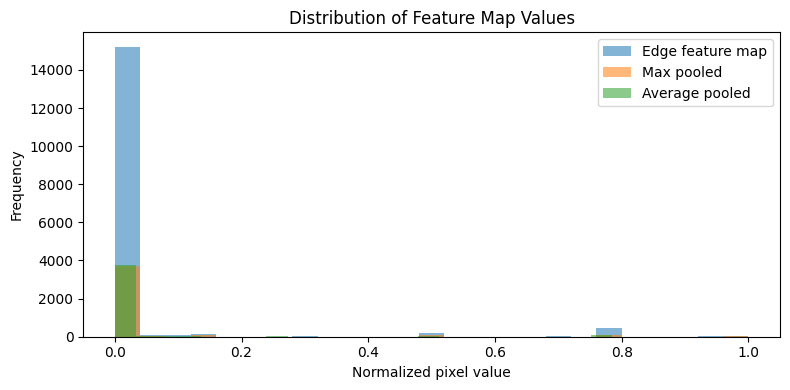

In [6]:
plt.figure(figsize=(8, 4))
plt.hist(edge_display.ravel(), bins=25, alpha=0.55, label="Edge feature map")
plt.hist(max_pooled.ravel(), bins=25, alpha=0.55, label="Max pooled")
plt.hist(avg_pooled.ravel(), bins=25, alpha=0.55, label="Average pooled")
plt.xlabel("Normalized pixel value")
plt.ylabel("Frequency")
plt.title("Distribution of Feature Map Values")
plt.legend()
plt.tight_layout()
plt.show()

###Result
Convolution filters and max/average pooling were applied successfully to a sample image. The visualizations show the original image, feature maps, pooled outputs, and the reduction in image dimensions.